# Customer Churn Prediction: End-to-End Capstone

**Business problem:** A subscription company loses customers every month. Winning a new customer costs far more than keeping an existing one, so the company wants to **find customers who are about to leave and contact them first**.

**Goal:** Build a model that predicts churn, turn it into a web app, and estimate the money a retention campaign could save.

**Success metrics**
| Metric | Target | Why |
|---|---|---|
| ROC-AUC | >= 0.90 | Ranks risky customers above safe ones |
| Recall (churn class) | >= 0.80 | Missing a churner costs more than a wasted offer |
| Net benefit of campaign | > 0 | The project must pay for itself |

**Workflow:** setup -> data quality -> EDA -> features -> model comparison -> tuning -> evaluation -> business impact -> deployment demo -> recommendations.

## 1. Setup
Run this notebook from the **project root folder** (the folder that contains `src/` and `data/`).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict

from src.config import *
from src.data_loader import load_data, validate_data
from src.features import add_features
from src.train import FEATURES, get_candidates, make_pipeline
from src.evaluate import evaluate_model, get_importances
from src.business import retention_impact, churn_by_group

sns.set_theme(style="whitegrid", palette="viridis")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Setup complete")

Setup complete


## 2. Data collection and quality check
The data comes from the task portal (`customer_churn.csv`): 500 customers, one row each.

In [2]:
df = load_data()
print("Shape:", df.shape)
df.head()

Shape: (500, 9)


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


In [3]:
quality = validate_data(df)
print(json.dumps(quality, indent=2))

{
  "rows": 500,
  "columns": 9,
  "missing_columns": [],
  "missing_values": 0,
  "duplicate_rows": 0,
  "duplicate_ids": 0,
  "churn_rate": 0.106,
  "negative_numeric_values": 0,
  "passed": true
}


### Data dictionary
| Column | Type | Meaning |
|---|---|---|
| CustomerID | text | Unique customer code (not used for modeling) |
| Tenure | integer | Months the customer has stayed |
| MonthlyCharges | integer | Amount billed per month |
| TotalCharges | integer | Total amount billed so far |
| Contract | category | Month-to-month, One year, Two year |
| PaymentMethod | category | Bank Transfer, Credit Card, Electronic Check |
| PaperlessBilling | category | Yes / No |
| SeniorCitizen | 0/1 | 1 if senior citizen |
| **Churn** | 0/1 | **Target.** 1 = customer left |

**Quality result:** no missing values, no duplicates, no negative numbers.

**Note:** `TotalCharges` is not exactly `Tenure x MonthlyCharges`, so this is a *simulated* dataset. We keep that in mind when we interpret results.

## 3. Exploratory data analysis

In [4]:
df.describe().round(1)

,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
count,500.0,500.0,500.0,500.0,500.0
mean,36.5,113.6,4237.9,0.5,0.1
std,20.7,51.8,2260.6,0.5,0.3
min,1.0,20.0,159.0,0.0,0.0
25%,19.0,67.0,2237.2,0.0,0.0
50%,37.0,115.0,4182.5,0.0,0.0
75%,54.0,158.0,6266.8,1.0,0.0
max,71.0,199.0,7992.0,1.0,1.0


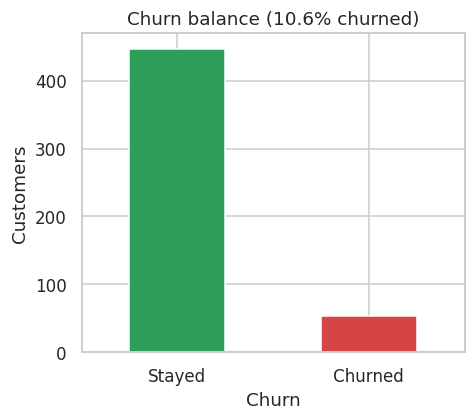

In [5]:
rate = df["Churn"].mean()
fig, ax = plt.subplots(figsize=(4.5, 4))
df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(ax=ax, color=["#2E9E5B", "#D64545"])
ax.set_title(f"Churn balance ({rate:.1%} churned)")
ax.set_ylabel("Customers"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_churn_balance.png", dpi=150); plt.show()

**Insight:** only about 1 in 10 customers churn. The classes are imbalanced, so accuracy alone is misleading. We will watch recall and ROC-AUC.

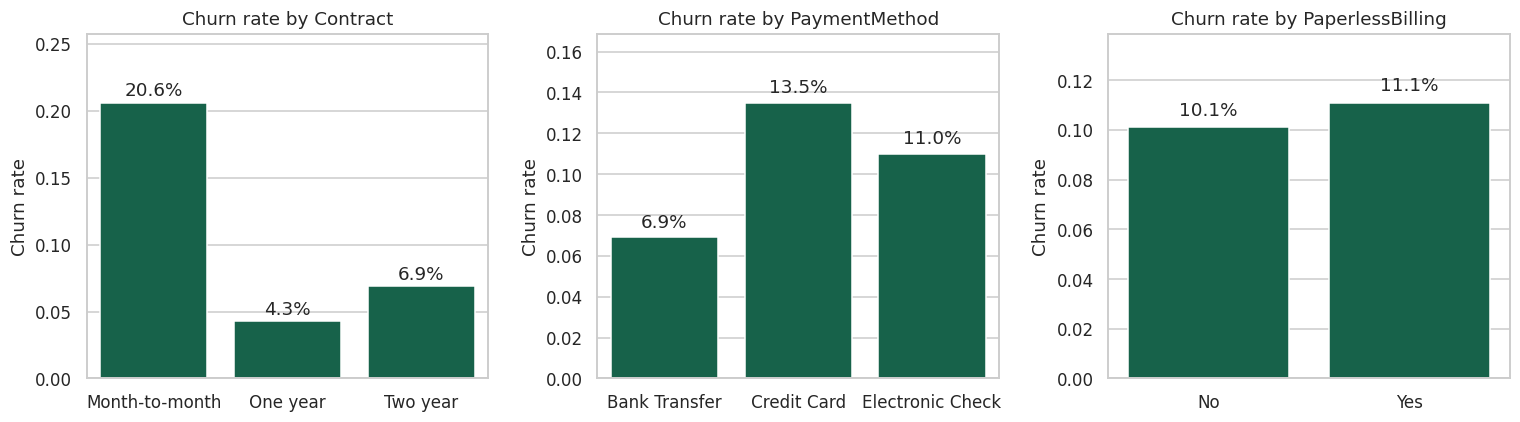

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Contract", "PaymentMethod", "PaperlessBilling"]):
    g = churn_by_group(df, col)
    sns.barplot(data=g, x=col, y="churn_rate", ax=ax, color="#0B6E4F")
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate"); ax.set_xlabel("")
    ax.set_ylim(0, g["churn_rate"].max() * 1.25)
    for i, v in enumerate(g["churn_rate"]):
        ax.text(i, v + 0.005, f"{v:.1%}", ha="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_categorical.png", dpi=150); plt.show()

**Insight:** month-to-month customers churn about 3-5x more than customers on one- or two-year contracts.

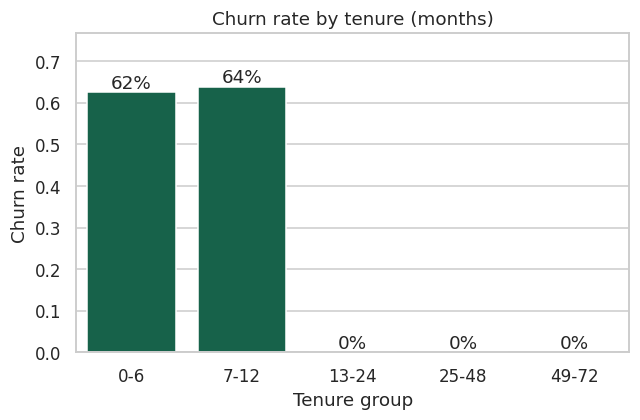

In [7]:
df["TenureGroup"] = pd.cut(df["Tenure"], [0, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
g = df.groupby("TenureGroup", observed=True)["Churn"].mean().reset_index()
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=g, x="TenureGroup", y="Churn", ax=ax, color="#0B6E4F")
ax.set_title("Churn rate by tenure (months)"); ax.set_ylabel("Churn rate"); ax.set_xlabel("Tenure group")
ax.set_ylim(0, g["Churn"].max() * 1.2)
for i, v in enumerate(g["Churn"]):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_tenure.png", dpi=150); plt.show()
df = df.drop(columns="TenureGroup")

**Key pattern:** customers who stay beyond **12 months** essentially never churn in this data. All of the churn happens in the first year. The first year is the danger zone.

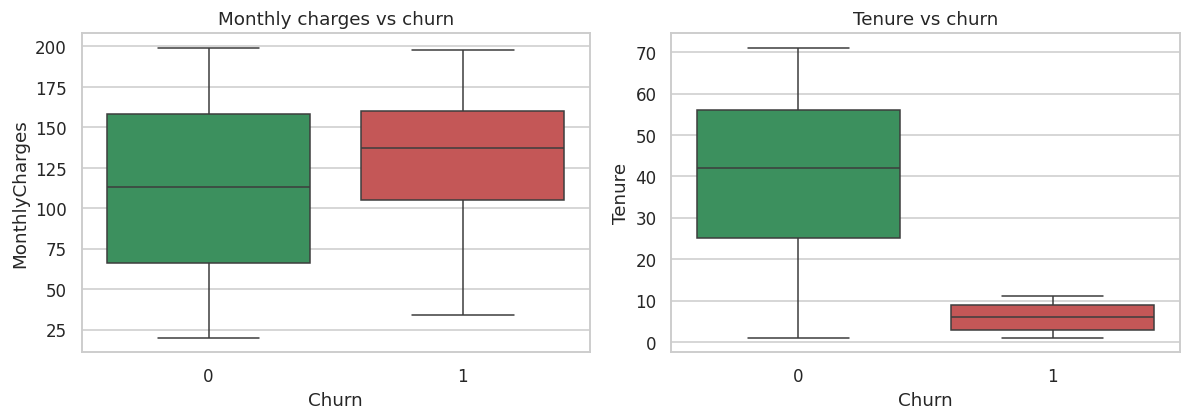

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[0], palette=["#2E9E5B", "#D64545"])
axes[0].set_title("Monthly charges vs churn")
sns.boxplot(data=df, x="Churn", y="Tenure", ax=axes[1], palette=["#2E9E5B", "#D64545"])
axes[1].set_title("Tenure vs churn")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_numeric.png", dpi=150); plt.show()

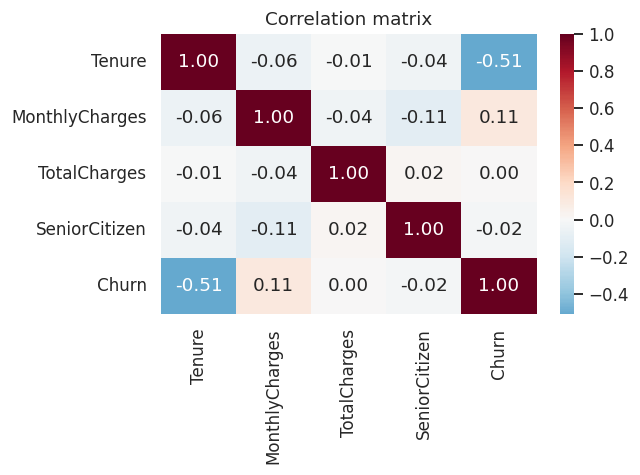

In [9]:
corr = df[["Tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]].corr()
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_correlation.png", dpi=150); plt.show()

**Summary of patterns**
1. All churn happens in the first 12 months.
2. Month-to-month contracts churn most.
3. Higher monthly charges raise churn risk.
4. Senior citizen status and paperless billing barely matter.

## 4. Feature engineering
We add three business-friendly features:
- `AvgMonthlySpend` = TotalCharges / Tenure
- `IsNewCustomer` = 1 if tenure <= 12 months
- `HighCharges` = 1 if monthly charges > 100

In [10]:
data = add_features(df)
data[["Tenure", "MonthlyCharges", "AvgMonthlySpend", "IsNewCustomer", "HighCharges", "Churn"]].head()

,Tenure,MonthlyCharges,AvgMonthlySpend,IsNewCustomer,HighCharges,Churn
0,6,64,256.666667,1,0,0
1,21,113,83.476190,0,1,0
2,27,31,53.888889,0,0,0
3,53,29,134.905660,0,0,0
4,16,185,63.937500,0,1,0


## 5. Train / test split and model comparison
We hold out 20% of the data as a test set that the models never see during training. Models are compared with 5-fold cross-validation on the training data only.

In [11]:
X, y = data[FEATURES], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in get_candidates().items():
    s = cross_val_score(make_pipeline(model), X_train, y_train, cv=cv, scoring="roc_auc")
    rows.append({"Model": name, "CV AUC (mean)": round(s.mean(), 4), "CV AUC (std)": round(s.std(), 4)})
comparison = pd.DataFrame(rows)
comparison

Train: (400, 10)  Test: (100, 10)


,Model,CV AUC (mean),CV AUC (std)
0,Logistic Regression,0.9922,0.0046
1,Random Forest,0.9928,0.0038
2,Gradient Boosting,0.9940,0.0060


All three models score above 0.99 AUC. This tells us the churn signal in this dataset is very clear and even a simple Logistic Regression captures it. We choose a **Random Forest** and tune it, because it is robust and gives feature importances that are easy to explain to business people.

## 6. Hyperparameter tuning

In [12]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
grid = GridSearchCV(
    make_pipeline(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    {"model__n_estimators": [100, 200, 300], "model__max_depth": [3, 5, None], "model__min_samples_leaf": [1, 3, 5]},
    cv=cv, scoring="roc_auc", n_jobs=1)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print("Best CV AUC:", round(grid.best_score_, 4))
best = grid.best_estimator_

Best parameters: {'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}
Best CV AUC: 0.9934


## 7. Final evaluation on the unseen test set

In [13]:
metrics = evaluate_model(best, X_test, y_test)
pd.Series({k: round(v, 3) for k, v in metrics.items() if k != "confusion_matrix"}, name="Test score").to_frame()

,Test score
accuracy,0.930
precision,0.611
recall,1.000
f1,0.759
roc_auc,0.997


              precision    recall  f1-score   support

        Stay       1.00      0.92      0.96        89
       Churn       0.61      1.00      0.76        11

    accuracy                           0.93       100
   macro avg       0.81      0.96      0.86       100
weighted avg       0.96      0.93      0.94       100


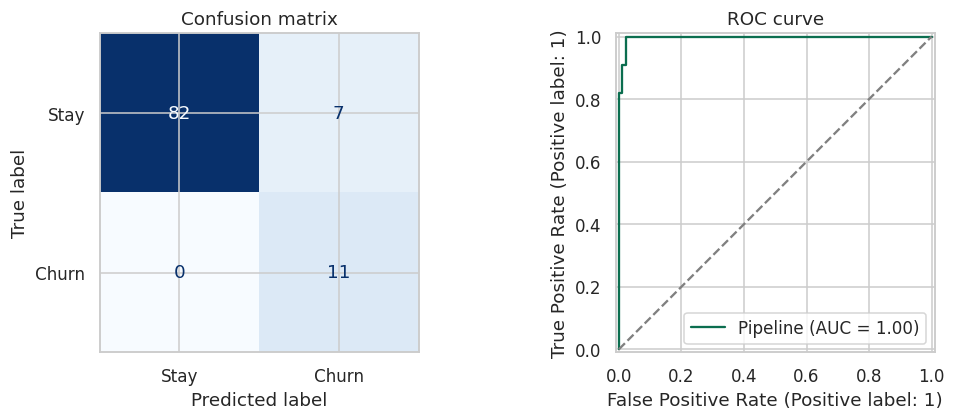

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=["Stay", "Churn"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_estimator(best, X_test, y_test, ax=axes[1], color="#0B6E4F")
axes[1].plot([0, 1], [0, 1], "--", color="grey"); axes[1].set_title("ROC curve")
plt.tight_layout(); plt.show()
print(classification_report(y_test, best.predict(X_test), target_names=["Stay", "Churn"]))

**Reading the results**
- **Recall = 1.00:** the model finds every churner in the test set.
- **Precision about 0.61:** roughly 4 in 10 flagged customers would have stayed anyway. That is the price of not missing churners, and a retention offer to a loyal customer is cheap compared with losing a customer.
- The test set has only 100 customers (about 11 churners), so these numbers can move a little with a different split. Cross-validation (AUC about 0.99) confirms the model is stable.
- These results are *unusually* high because the dataset is simulated with clear rules. Real company data would give lower scores.

## 8. What drives churn?

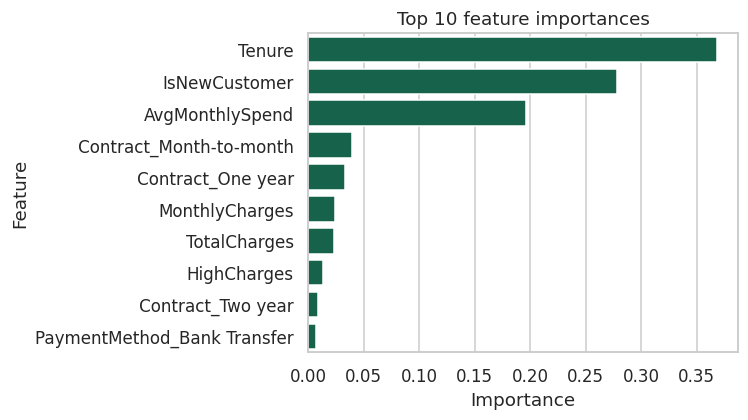

,Feature,Importance
0,Tenure,0.368
1,IsNewCustomer,0.278
2,AvgMonthlySpend,0.196
3,Contract_Month-to-month,0.039
4,Contract_One year,0.033
5,MonthlyCharges,0.024
6,TotalCharges,0.023
7,HighCharges,0.013
8,Contract_Two year,0.009
9,PaymentMethod_Bank Transfer,0.007


In [15]:
imp = pd.DataFrame(get_importances(best), columns=["Feature", "Importance"]).head(10)
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=imp, y="Feature", x="Importance", ax=ax, color="#0B6E4F")
ax.set_title("Top 10 feature importances")
plt.tight_layout(); plt.show()
imp.round(3)

Tenure, the new-customer flag and contract type dominate. This matches what the EDA showed, which is a good sign that the model learned real patterns.

## 9. Business impact
We score every customer with **out-of-fold predictions** (each customer is predicted by a model that never saw them), then compare *doing nothing* with *contacting every flagged customer*.

**Assumptions (change them in `src/business.py`):** a retention offer costs 10% of the customer's annual revenue, and 30% of contacted churners accept it and stay.

In [16]:
oof = cross_val_predict(make_pipeline(RandomForestClassifier(
    class_weight="balanced", random_state=RANDOM_STATE, **{k.split("__")[1]: v for k, v in grid.best_params_.items()})),
    X, y, cv=cv, method="predict")
impact = retention_impact(data["MonthlyCharges"], y, oof)
pd.Series(impact).drop("assumptions").to_frame("Value")

,Value
customers,500
actual_churners,53
customers_flagged,81
churners_caught,53
annual_revenue_at_risk,82536.0
campaign_cost,11444.4
revenue_saved,24760.8
net_benefit,13316.4


With these assumptions the campaign pays for itself. The exact rupee/dollar figure depends on the assumptions, so treat it as an estimate and update the two rates with real company numbers.

## 10. Save the final model and results

In [17]:
import joblib
joblib.dump({"pipeline": best, "features": FEATURES}, MODEL_PATH)
metrics.update({"best_params": grid.best_params_, "best_cv_auc": float(grid.best_score_)})
(ROOT / "reports" / "business_impact.json").write_text(json.dumps(impact, indent=2))
print("Saved:", MODEL_PATH.name, "and business_impact.json")

Saved: model.joblib and business_impact.json


## 11. Deployment demo
The saved model is served by a Flask app (`deployment/app.py`). Here we call the same prediction function the app uses.

In [18]:
from src.predict import predict_one, load_model
bundle = load_model()
new_customer = {"Tenure": 4, "MonthlyCharges": 140, "TotalCharges": 560, "SeniorCitizen": 0,
                "Contract": "Month-to-month", "PaymentMethod": "Electronic Check", "PaperlessBilling": "Yes"}
loyal_customer = {"Tenure": 48, "MonthlyCharges": 60, "TotalCharges": 2880, "SeniorCitizen": 1,
                  "Contract": "Two year", "PaymentMethod": "Bank Transfer", "PaperlessBilling": "No"}
print("New, month-to-month customer:", predict_one(new_customer, bundle))
print("Loyal, two-year customer    :", predict_one(loyal_customer, bundle))

New, month-to-month customer: {'churn_probability': 0.8372, 'prediction': 1, 'risk_level': 'High'}
Loyal, two-year customer    : {'churn_probability': 0.0283, 'prediction': 0, 'risk_level': 'Low'}


## 12. Business recommendations
1. **Focus on the first 12 months.** Run onboarding calls and check-ins in months 1-12. After month 12 churn is almost zero.
2. **Move month-to-month customers to longer contracts.** Offer a small discount for a one-year plan.
3. **Watch high-bill new customers.** Customers paying over 100 per month in their first year are the highest risk. Review their pricing early.
4. **Use the model as a weekly watch-list.** Score new customers every week and send the "High" risk list to the retention team.
5. **Measure and improve.** Track how many contacted customers stay, then replace the two assumptions in `src/business.py` with real numbers.

**Limitations:** the data is small (500 rows) and simulated, there is no information about service quality or complaints, and the near-perfect scores will not carry over to real data. Next steps: collect richer data, test on a live customer sample, and retrain every quarter.